# Drift vs Model Performance on IEEE-CIS
The TA asked us to check whether model performance drops over time windows, and to compare that with the KS / PSI drift measures. Notebook 04b measured the drift per week and notebook 04c compared it with a simple model trained only on the early weeks. This notebook repeats the comparison with the group's actual models on the validation period (days 109 to 141):

- **Drift**: PSI and KS of each validation window against the rows the static model was trained on (the labelled days before day 102, i.e. day 109 minus the 7-day label delay), with the same `psi` function and the same 14 drift features as notebook 04b, plus the mean PSI over all numeric features

- **Performance**: PR-AUC per validation window of the static and M2 models with the 7-day delay, computed from the saved scores of notebook 05 (LR, RF, CatBoost) and notebook 05c (LightGBM). As a check, the weekly PR-AUC of LR, RF and CatBoost is compared with the weekly table in notebook 05 Section 9.4

- **Questions**:
    1. Do the weeks with more drift have lower static PR-AUC?
    2. Is the M2 gain larger in the weeks with more drift?
    3. Does the static model follow the drift score of each window, or the time since it was trained?

Note: the fraud rate also changes between weeks (notebook 04b Section 2), and PR-AUC depends on it (a random model gets the fraud rate). So we also look at PR-AUC divided by the window's fraud rate (the lift over a random ranking)

`data/interim/m2_scores_refit/` must have the validation runs of notebook 05 and notebook 05c (the `val_static_*_delay7` and `val_m2_*_delay7` files)

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp, spearmanr
from sklearn.metrics import average_precision_score

pd.set_option("display.max_columns", 100)

PROCESSED_DIR = Path("../data/processed")
SCORES_DIR = Path("../data/interim/m2_scores_refit")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

LABEL_DELAY_DAYS = 7

## 1. Load the Features
Only the numeric model inputs are needed for the drift measures, so the categorical columns are not converted here. The rows and their order are the same as in notebooks 05 and 05c

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]
feature_cols = feature_lists["ieee_feature_cols"]
num_cols = [c for c in feature_cols if c not in feature_lists["ieee_categorical_cols"] and c not in CODE_AS_CATEGORY]

features = features.loc[features["ieee_split"].isin(["train", "validation"]), num_cols + ["isFraud", "ieee_split", "TransactionDT"]]
features = features.astype({c: "float32" for c in num_cols}).copy()
features["day"] = features["TransactionDT"] // 86400

train = features[features["ieee_split"] == "train"]
val = features[features["ieee_split"] == "validation"]
del features

VAL_FIRST_DAY = int(val["day"].min())
STATIC_TRAIN_END = VAL_FIRST_DAY - LABEL_DELAY_DAYS   # the static model with the 7-day delay trains on days before this one
reference = train[train["day"] < STATIC_TRAIN_END]
val = val.assign(week=(val["day"] - VAL_FIRST_DAY) // 7 + 1)

print(f"reference rows: {len(reference):,} (days {int(reference['day'].min())} to {int(reference['day'].max())})")
print(f"validation rows: {len(val):,} (days {VAL_FIRST_DAY} to {int(val['day'].max())}, {val['week'].nunique()} weeks)")
print("numeric features:", len(num_cols))

reference rows: 356,216 (days 1 to 101)
validation rows: 94,487 (days 109 to 141, 5 weeks)
numeric features: 528


## 2. Drift per Validation Week
Same `psi` function as notebook 04b: values are binned at the reference deciles, missing values get their own bin, and PSI below 0.1 is stable, 0.1 to 0.25 a moderate shift and above 0.25 a large shift. KS is the largest gap between the two cumulative distributions

In [3]:
def psi(reference, current, bins=10, eps=1e-4):
    ref = pd.Series(reference, dtype=float)
    cur = pd.Series(current, dtype=float)
    edges = np.unique(np.nanquantile(ref.dropna(), np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:                      # almost constant feature: compare value shares instead
        edges = np.unique(np.concatenate([edges, [edges[-1] + 1]]))
    edges[0], edges[-1] = -np.inf, np.inf

    def shares(s):
        counts = np.histogram(s.dropna(), bins=edges)[0].astype(float)
        counts = np.append(counts, s.isna().sum())      # missing values = extra bin
        return np.clip(counts / max(len(s), 1), eps, None)

    r, c = shares(ref), shares(cur)
    return float(np.sum((c - r) * np.log(c / r)))


# the 14 IEEE-CIS features tracked in notebook 04b
DRIFT_FEATURES = ["TransactionAmt"] + [f"C{i}" for i in (1, 2, 5, 8, 9, 10, 13, 14)] + [f"D{i}" for i in (1, 2, 4, 10, 15)]

rows = []
for week, cur in val.groupby("week"):
    for f in num_cols:
        row = {"week": week, "feature": f, "psi": psi(reference[f], cur[f])}
        if f in DRIFT_FEATURES:
            x, y = reference[f].dropna(), cur[f].dropna()
            row["ks"] = ks_2samp(x, y).statistic if len(x) > 20 and len(y) > 20 else np.nan
        rows.append(row)
drift = pd.DataFrame(rows)

print("PSI of the 04b drift features per validation week:")
display(drift[drift["feature"].isin(DRIFT_FEATURES)].pivot(index="feature", columns="week", values="psi").reindex(DRIFT_FEATURES).round(3))

weekly_drift = pd.DataFrame({
    "mean PSI (04b features)": drift[drift["feature"].isin(DRIFT_FEATURES)].groupby("week")["psi"].mean(),
    "mean KS (04b features)": drift[drift["feature"].isin(DRIFT_FEATURES)].groupby("week")["ks"].mean(),
    "mean PSI (all numeric)": drift.groupby("week")["psi"].mean(),
    "share of features with PSI > 0.25": drift.groupby("week")["psi"].apply(lambda v: (v > 0.25).mean()),
})
weekly_drift["fraud rate"] = val.groupby("week")["isFraud"].mean()
weekly_drift["rows"] = val.groupby("week").size()
display(weekly_drift.round(4))

PSI of the 04b drift features per validation week:


week,1,2,3,4,5
feature,,,,,
TransactionAmt,0.012,0.010,0.016,0.010,0.014
C1,0.004,0.002,0.018,0.010,0.017
C2,0.009,0.011,0.029,0.022,0.025
C5,0.001,0.001,0.027,0.010,0.025
C8,0.023,0.011,0.068,0.045,0.055
C9,0.068,0.050,0.147,0.103,0.106
C10,0.023,0.016,0.068,0.045,0.058
C13,0.010,0.009,0.052,0.034,0.042
C14,0.003,0.002,0.019,0.010,0.019


,mean PSI (04b features),mean KS (04b features),mean PSI (all numeric),share of features with PSI > 0.25,fraud rate,rows
week,,,,,,
1,0.0382,0.0482,0.0674,0.0511,0.0452,20024
2,0.0367,0.0461,0.0688,0.0549,0.0446,22097
3,0.0502,0.0860,0.0785,0.0549,0.0336,22300
4,0.0522,0.0786,0.0698,0.0360,0.0384,18482
5,0.0483,0.0837,0.0706,0.0511,0.0306,11584


**Takeaway: Drift per Week**
- Against the days the static model was trained on (days 1 to 101), the average drift is small in every validation week: the mean PSI of the 14 features from notebook 04b is 0.037 to 0.052, well below the 0.1 "moderate shift" level. Only about 4% to 5% of all numeric features have a PSI above 0.25 in any week

- The drift sits in a few columns: `C9` reaches 0.147 in week 3, `D1` 0.221 in week 4, and `D4`, `D10` and `D15` are around 0.1 to 0.16 in the first two weeks. `TransactionAmt`, `C1` and `C14` stay below 0.02 => the same columns that drifted most in notebook 04b

- The mean PSI rises a little after week 2 (0.037 to about 0.05), **BUT** it does not keep growing week after week

- The fraud rate falls from 4.5% in weeks 1 and 2 to 3.1% in week 5, so the weekly PR-AUC values below are also compared as a lift over the fraud rate

## 3. Model Performance per Validation Week
Every family is scored from its saved runs. Each family uses the retraining setting chosen by its own simulation on the training days (LR every 7 days on the last 56 days, the others every 7 days on all earlier days). Weeks start on day 109, and week 5 has 5 days

In [4]:
y_val = val["isFraud"].to_numpy()
week = val["week"].to_numpy()


def load_scores(run_name):
    # the saved scores are indexed by the rows of the training and validation frame, so we select the validation rows
    return pd.read_pickle(SCORES_DIR / f"{run_name}.pkl").loc[val.index].to_numpy()


RUNS = {
    "LR": ("val_static_LR_window56_delay7", "val_m2_LR_freq7_window56_delay7"),
    "RF": ("val_static_RF_windowall_delay7", "val_m2_RF_freq7_windowall_delay7"),
    "LightGBM": ("val_static_LightGBM_windowall_delay7", "val_m2_LightGBM_freq7_windowall_delay7"),
    "CatBoost": ("val_static_CatBoost_windowall_delay7", "val_m2_CatBoost_freq7_windowall_delay7"),
}
FAMILIES = list(RUNS)
runs = {(family, run): load_scores(name) for family, names in RUNS.items() for run, name in zip(["static", "M2"], names)}

weekly_rows = []
for (family, run), scores in runs.items():
    for w in range(1, 6):
        rows_w = week == w
        weekly_rows.append({"family": family, "run": run, "week": w, "PR-AUC": average_precision_score(y_val[rows_w], scores[rows_w])})

# check: the weekly PR-AUC in notebook 05 Section 9.4
notebook_05_weekly = {
    ("LR", "static"): [0.5520, 0.5291, 0.5545, 0.4298, 0.3239],
    ("LR", "M2"): [0.5520, 0.5215, 0.5626, 0.4816, 0.3569],
    ("RF", "static"): [0.5923, 0.5800, 0.6022, 0.4383, 0.4079],
    ("RF", "M2"): [0.5923, 0.5874, 0.6114, 0.4882, 0.4515],
    ("CatBoost", "static"): [0.6749, 0.6062, 0.6313, 0.5323, 0.4437],
    ("CatBoost", "M2"): [0.6749, 0.6480, 0.6851, 0.6481, 0.5733],
}
check = pd.DataFrame(weekly_rows).set_index(["family", "run", "week"])["PR-AUC"]
largest_gap = max(abs(check[(family, run, w + 1)] - value) for (family, run), values in notebook_05_weekly.items() for w, value in enumerate(values))
print(f"largest gap to the weekly table of notebook 05: {largest_gap:.4f}")

weekly_perf = pd.DataFrame(weekly_rows)
perf_table = weekly_perf.pivot_table(index=["family", "run"], columns="week", values="PR-AUC", sort=False)
display(perf_table.round(4))

# lift over a random ranking: PR-AUC divided by the week's fraud rate
weekly_perf["lift"] = weekly_perf["PR-AUC"] / weekly_perf["week"].map(weekly_drift["fraud rate"])
print("PR-AUC / fraud rate of the week:")
display(weekly_perf.pivot_table(index=["family", "run"], columns="week", values="lift", sort=False).round(2))

largest gap to the weekly table of notebook 05: 0.0000


week                  1       2       3       4       5
family   run                                           
LR       static  0.5520  0.5291  0.5545  0.4298  0.3239
         M2      0.5520  0.5215  0.5626  0.4816  0.3569
RF       static  0.5923  0.5800  0.6022  0.4383  0.4079
         M2      0.5923  0.5874  0.6114  0.4882  0.4515
LightGBM static  0.6391  0.5801  0.6180  0.5059  0.4020
         M2      0.6391  0.6033  0.6637  0.6148  0.5109
CatBoost static  0.6749  0.6062  0.6313  0.5323  0.4437
         M2      0.6749  0.6480  0.6851  0.6481  0.5733

PR-AUC / fraud rate of the week:


week                 1      2      3      4      5
family   run                                      
LR       static  12.21  11.87  16.49  11.19  10.60
         M2      12.21  11.70  16.73  12.54  11.68
RF       static  13.11  13.01  17.90  11.41  13.35
         M2      13.11  13.18  18.18  12.71  14.77
LightGBM static  14.14  13.01  18.38  13.17  13.15
         M2      14.14  13.53  19.73  16.00  16.72
CatBoost static  14.93  13.60  18.77  13.86  14.52
         M2      14.93  14.54  20.37  16.87  18.76

## 4. Drift vs Performance
### 4.1 Chart
PR-AUC of each family's static model (dashed) and M2 model (solid) per week, with the mean PSI of the 04b features on the right axis

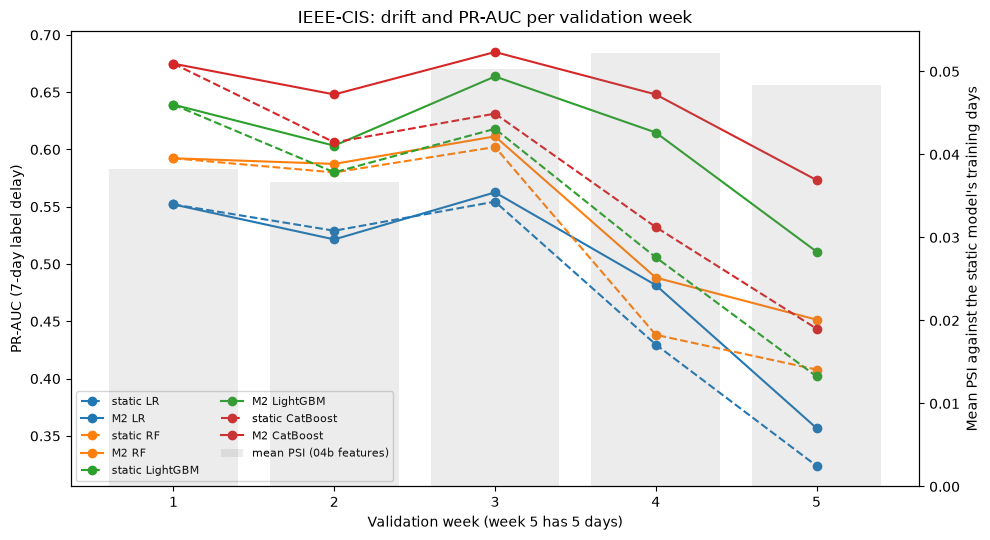

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = dict(zip(FAMILIES, plt.cm.tab10.colors))
for family in FAMILIES:
    for run, style in [("static", "--"), ("M2", "-")]:
        data = weekly_perf[(weekly_perf["family"] == family) & (weekly_perf["run"] == run)]
        ax.plot(data["week"], data["PR-AUC"], style, marker="o", color=colors[family], label=f"{run} {family}")
ax.set_xlabel("Validation week (week 5 has 5 days)")
ax.set_ylabel("PR-AUC (7-day label delay)")
ax.set_xticks(range(1, 6))

ax2 = ax.twinx()
ax2.bar(weekly_drift.index, weekly_drift["mean PSI (04b features)"], alpha=0.15, color="grey", label="mean PSI (04b features)")
ax2.set_ylabel("Mean PSI against the static model's training days")
ax2.grid(False)

lines, labels = ax.get_legend_handles_labels()
bars, bar_labels = ax2.get_legend_handles_labels()
ax.legend(lines + bars, labels + bar_labels, fontsize=8, ncol=2, loc="lower left")
ax.set_title("IEEE-CIS: drift and PR-AUC per validation week")
plt.tight_layout()
fig.savefig(FIG_DIR / "05d_drift_vs_pr_auc_by_week.png", bbox_inches="tight")
plt.show()

### 4.2 Correlations
For each family, Spearman correlation over the 5 weeks between:
- the week's mean PSI and the static model's PR-AUC (question 1, expected negative if drift hurts the static model)

- the week's mean PSI and the M2 gain (M2 - static PR-AUC, question 2, expected positive if retraining helps most where the drift is largest)

- the week number and the static model's PR-AUC (question 3: does performance follow the time since training instead?)

With only 5 weeks, a correlation needs to be close to -1 or 1 to mean much, so these numbers only show the direction. Section 4.3 uses shorter windows to get more points

In [6]:
psi_by_week = weekly_drift["mean PSI (04b features)"]
corr_rows = []
for family in FAMILIES:
    static = weekly_perf[(weekly_perf["family"] == family) & (weekly_perf["run"] == "static")].set_index("week")["PR-AUC"]
    m2 = weekly_perf[(weekly_perf["family"] == family) & (weekly_perf["run"] == "M2")].set_index("week")["PR-AUC"]
    static_lift = static / weekly_drift["fraud rate"]
    corr_rows.append({
        "family": family,
        "PSI vs static PR-AUC": spearmanr(psi_by_week, static).statistic,
        "PSI vs static lift": spearmanr(psi_by_week, static_lift).statistic,
        "PSI vs M2 gain": spearmanr(psi_by_week, m2 - static).statistic,
        "week vs static PR-AUC": spearmanr(static.index, static).statistic,
    })
display(pd.DataFrame(corr_rows).set_index("family").round(2))

,PSI vs static PR-AUC,PSI vs static lift,PSI vs M2 gain,week vs static PR-AUC
family,,,,
LR,-0.1,-0.1,0.9,-0.7
RF,-0.1,0.0,0.8,-0.7
LightGBM,-0.3,0.5,0.6,-0.9
CatBoost,-0.3,0.3,0.6,-0.9


### 4.3 Shorter Windows
To get more than 5 points, we split the validation period into 3-day windows (11 windows) and repeat the comparison for every family. The models stay the same (7-day delay, retrained every 7 days), only the PR-AUC is computed on shorter windows. PR-AUC on a few days is noisier, so we also report the lift over the window's fraud rate

In [7]:
WINDOW_DAYS = 3
window = (val["day"].to_numpy() - VAL_FIRST_DAY) // WINDOW_DAYS
window_rows = []
for w in np.unique(window):
    rows_w = window == w
    cur = val[rows_w]
    window_rows.append({
        "window": int(w) + 1,
        "days": f"{VAL_FIRST_DAY + w * WINDOW_DAYS}-{min(VAL_FIRST_DAY + (w + 1) * WINDOW_DAYS - 1, int(val['day'].max()))}",
        "rows": int(rows_w.sum()),
        "fraud rate": y_val[rows_w].mean(),
        "mean PSI (04b features)": np.mean([psi(reference[f], cur[f]) for f in DRIFT_FEATURES]),
    })
short = pd.DataFrame(window_rows).set_index("window")

short_perf = {}
for (family, run), scores in runs.items():
    short_perf[(family, run)] = pd.Series({int(w) + 1: average_precision_score(y_val[window == w], scores[window == w]) for w in np.unique(window)})
short_perf = pd.DataFrame(short_perf)
display(short.round(4))
print("PR-AUC per 3-day window:")
display(short_perf.T.round(3))

corr_rows = []
for family in FAMILIES:
    static, m2 = short_perf[(family, "static")], short_perf[(family, "M2")]
    corr_rows.append({
        "family": family,
        "PSI vs static PR-AUC": spearmanr(short["mean PSI (04b features)"], static).statistic,
        "PSI vs static lift": spearmanr(short["mean PSI (04b features)"], static / short["fraud rate"]).statistic,
        "PSI vs M2 gain": spearmanr(short["mean PSI (04b features)"], m2 - static).statistic,
        "window vs static PR-AUC": spearmanr(short.index, static).statistic,
        "window vs M2 gain": spearmanr(short.index, m2 - static).statistic,
    })
print(f"Spearman correlation over {len(short)} windows:")
display(pd.DataFrame(corr_rows).set_index("family").round(2))
print("window vs PSI:", round(spearmanr(short.index, short["mean PSI (04b features)"]).statistic, 2))

,days,rows,fraud rate,mean PSI (04b features)
window,,,,
1,109-111,8353,0.0378,0.0513
2,112-114,9210,0.0489,0.0327
3,115-117,8614,0.0576,0.0406
4,118-120,10420,0.0425,0.0385
5,121-123,8914,0.0351,0.0577
6,124-126,10720,0.0316,0.0716
7,127-129,8190,0.0346,0.0452
8,130-132,8381,0.0367,0.0792
9,133-135,8053,0.0409,0.0423


PR-AUC per 3-day window:


1      2      3      4      5      6      7      8   \
LR       static  0.530  0.535  0.632  0.472  0.577  0.570  0.485  0.381   
         M2      0.530  0.535  0.624  0.466  0.575  0.583  0.488  0.470   
RF       static  0.572  0.590  0.686  0.505  0.623  0.626  0.531  0.381   
         M2      0.572  0.590  0.684  0.518  0.627  0.639  0.539  0.448   
LightGBM static  0.650  0.610  0.689  0.487  0.683  0.623  0.565  0.436   
         M2      0.650  0.610  0.697  0.525  0.702  0.676  0.609  0.575   
CatBoost static  0.678  0.644  0.734  0.509  0.687  0.652  0.548  0.460   
         M2      0.678  0.644  0.741  0.574  0.718  0.707  0.614  0.626   

                    9      10     11  
LR       static  0.506  0.378  0.300  
         M2      0.509  0.402  0.333  
RF       static  0.525  0.451  0.378  
         M2      0.547  0.492  0.414  
LightGBM static  0.607  0.443  0.377  
         M2      0.671  0.567  0.469  
CatBoost static  0.631  0.476  0.410  
         M2      0.689  0.603  0.540

Spearman correlation over 11 windows:


,PSI vs static PR-AUC,PSI vs static lift,PSI vs M2 gain,window vs static PR-AUC,window vs M2 gain
family,,,,,
LR,-0.05,0.44,0.54,-0.69,0.75
RF,-0.05,0.44,0.40,-0.68,0.84
LightGBM,-0.05,0.50,0.49,-0.73,0.92
CatBoost,-0.05,0.50,0.33,-0.73,0.85


window vs PSI: 0.31


## 5. Takeaways
- **Check**: the weekly PR-AUC computed from the saved scores matches the weekly table of notebook 05 exactly (largest gap 0.0000), so the score files are the same runs

- **The static models lose performance with time, not with the drift score of each window**:
    - weekly: the correlation between the week number and the static PR-AUC is -0.7 (LR, RF) to -0.9 (LightGBM, CatBoost), while the correlation between the week's mean PSI and the static PR-AUC is only -0.1 to -0.3
    - 3-day windows: -0.68 to -0.73 for the window number vs -0.05 for the mean PSI, for every family
    - => this repeats notebook 04c with the group's actual models: performance decays as the gap since training grows, and the week-to-week PSI barely tracks it (04c: correlation 0.16 and -0.12)

- **The M2 gain also grows with time**: the correlation between the window number and the M2 gain (M2 - static PR-AUC) is 0.75 to 0.92, stronger than with the mean PSI (0.33 to 0.54 on 3-day windows). For CatBoost the gain goes from 0 in week 1 to +0.12 in week 4 and +0.13 in week 5. The PSI link is positive **BUT** weaker, and part of it comes from the PSI also rising a little over time (window vs PSI 0.31)

- **Why the PSI does not explain the decay**: PSI only measures whether the inputs change (covariate drift). Notebook 04b also found concept drift on IEEE-CIS (the fraud rate within the same feature bins changes between the early and late halves), which PSI cannot see. The average PSI stays low while the static models keep getting worse, which points to the relationship between features and fraud changing over time

- **For the report**: answers the TA's question => yes, performance drops over the validation windows, **BUT** the drop follows the time since training rather than the measured drift of each window. So a rule like "retrain when PSI goes above 0.25" would not have triggered here, while retraining on a fixed schedule (M2, every 7 days) recovers most of the loss. The chart is saved as `reports/figures/05d_drift_vs_pr_auc_by_week.png`

- **Limits**: 5 weeks and 11 three-day windows are few points, so the correlations show the direction rather than a precise size. The fraud rate also changes between windows, and the PR-AUC of short windows is noisy